# Pharmacy Closures and Neighborhood Access in Philadelphia
## Spatial assessment and research record
**Emmanuel Amissah Sampson · University of Pennsylvania**  
Urban studies research project · 16 November 2026

**Research status: executed public-data feasibility pilot.** This notebook preserves the supplementary inventory-removal experiment. The main dated analysis is in notebook 04. It does not estimate the historical causal effects of the 2023–2025 Rite Aid closures. A separate ledger now contains company-reported 2025 dates; a complete operating history and licensed human-mobility panel remain unavailable.

The completed calculation removes Rite Aid-labelled entries from a licensed-pharmacy roster. It measures a hypothetical change in straight-line proximity from tract centroids. All results must retain that interpretation.

## 1. Questions and scope
The eventual study asks how pharmacy closures alter destinations, sampled travel patterns, nearby demand and unequal access. Philadelphia pharmacies are the semester-sized case; other retail openings and relocations remain the longer-term agenda.

This public pilot answers three narrower questions:
1. Can we assemble a reproducible spatial analysis from accessible public data?
2. How sensitive is a removal scenario to the definition of the candidate pharmacy inventory?
3. Do baseline access and neighborhood features predict the scenario better than a simple median?

Observed travel mode and emissions changes are not identified by these data.

In [1]:
from pathlib import Path
import sys, json, hashlib
ROOT = Path.cwd()
if not (ROOT / 'config.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'config.json').exists(), 'Open this notebook inside the project folder'
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
pd.set_option('display.max_columns', 12)


## 2. Provenance and checks
The source manifest records exact URLs, retrieval times, licenses and hashes. Six official bulk ACS tables were streamed and filtered to Philadelphia tract rows. This route does not require a Census API key. Analytical source inputs are kept in `data/raw`; these are included in the project archive but excluded from Git. The optional insurer notice is a contextual reference, excluded from the archive; its source URL remains in the manifest.

If starting from a Git clone, first run `python -m src.download` at the project root. This notebook stops if required analytical inputs are missing or their recorded bytes have changed. The contextual insurer notice is optional and is not used to calculate results.

In [2]:
manifest = json.loads((ROOT / 'data/source_manifest.json').read_text())
for item in manifest:
    path = ROOT / item['local_path']
    if item['id'] == 'closure_notice_2025' and not path.exists():
        print('Optional insurer reference PDF not included; source URL retained in manifest.')
        continue
    assert item['status'] != 'failed', item['id']
    assert path.exists(), f'Missing {path}; run python -m src.download'
    assert hashlib.sha256(path.read_bytes()).hexdigest() == item['sha256'], f'Changed input: {path}'
display(pd.DataFrame(manifest)[['id','status','rows','local_path']].fillna(''))
print('Every required analytical input and available reference matches its recorded SHA-256 hash.')

<ipython-input-2-0390667aa9ad>:10: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(pd.DataFrame(manifest)[['id','status','rows','local_path']].fillna(''))


,id,status,rows,local_path
0,pa_pharmacies,downloaded,,data/raw/pa_pharmacies.csv
1,tract_boundaries,downloaded,,data/raw/cb_2022_42_tract_500k.zip
2,nj_county_boundaries,downloaded,,data/raw/cb_2022_us_county_500k.zip
3,closure_notice_2025,downloaded,,data/raw/rite_aid_closure_notice_2025.pdf
4,acs2022_B01003,downloaded,408.0,data/raw/acs2022_b01003_philadelphia.dat
5,acs2022_B19013,downloaded,408.0,data/raw/acs2022_b19013_philadelphia.dat
6,acs2022_B17001,downloaded,408.0,data/raw/acs2022_b17001_philadelphia.dat
7,acs2022_B08201,downloaded,408.0,data/raw/acs2022_b08201_philadelphia.dat
8,acs2022_B03002,downloaded,408.0,data/raw/acs2022_b03002_philadelphia.dat
9,acs2022_B01001,downloaded,408.0,data/raw/acs2022_b01001_philadelphia.dat


Every required analytical input and available reference matches its recorded SHA-256 hash.


## 3. Join geography, demographics and the candidate inventory
ACS estimates describe 2018–2022. We preserve margins of error and turn negative sentinel values into missing values. The denominator for no-vehicle share is households; the poverty denominator is the population for whom poverty status is determined.

Distances use EPSG:26918 (meters). Origins are projected geometric tract centroids, not people's actual homes. PA destinations in a 10 km city buffer are included. Fifty populated tract centers are less than 2 km from New Jersey county geometry and are flagged because NJ pharmacies are missing. All 391 populated tracts remain in the maps and primary proximity results. Only the secondary prediction comparison excludes the 50 flagged tracts, leaving 341. The 2 km rule checks data coverage; it is not a walking threshold and does not correct every cross-border bias.

In [3]:
from src.accessibility import prepare
tracts, pharmacies, quality = prepare()
display(pd.Series(quality, name='count').to_frame())
print('Analysis CRS:', tracts.crs)
display(tracts[['GEOID','population','poverty_rate','no_vehicle_share','age65plus_share','near_nj_2km']].head())

,count
registry_rows,3324
invalid_or_missing_coordinates,0
duplicate_licenses_removed,0
shared_geocode_rows,256
shared_address_rows,49
tracts_total,408
tracts_populated,391
study_buffer_registry_sites,817
rite_aid_labelled_buffer_sites,109
philadelphia_registry_sites,523


Analysis CRS: EPSG:26918


,GEOID,population,poverty_rate,no_vehicle_share,age65plus_share,near_nj_2km
0,42101001500,3251.0,0.061439,0.360319,0.080898,True
1,42101001800,3300.0,0.041212,0.196294,0.092424,True
2,42101002802,5720.0,0.183363,0.229132,0.146154,False
3,42101004001,4029.0,0.208488,0.234973,0.129312,False
4,42101006300,4415.0,0.394558,0.298373,0.066591,False


### What the inventory can and cannot tell us
A license entry is not necessarily an operating community pharmacy. The roster may retain inactive, inpatient-only or nonpublic dispensing locations. Some source geocodes are approximate; several records share addresses or coordinates. A Rite Aid name creates an **unverified closure candidate**, not a dated treatment event.

The code generates `closure_candidates_unverified.csv` with deliberately empty operating dates for manual verification. An announcement date is not automatically a pharmacy closure date.

In [4]:
candidates = pd.read_csv(ROOT / 'data/processed/closure_candidates_unverified.csv', dtype=str)
print(f'{len(candidates)} Rite Aid-labelled candidates in the PA study buffer; none has a verified event date in this run.')
display(candidates[['license_id','name','address','city','date_quality']].head(8))

109 Rite Aid-labelled candidates in the PA study buffer; none has a verified event date in this run.


,license_id,name,address,city,date_quality
0,PP410641L,Rite Aid #11104,1650 Limekiln Pike,Dresher,unverified
1,PP412931L,Rite Aid Pharmacy 1299,2503-05 Welsh Rd,Philadelphia,unverified
2,PP411564L,Rite Aid #11139,6515 Castor Avenue,Philadelphia,unverified
3,PP413411L,Rite Aid Pharmacy #0679,123 S 69Th Street,Upper Darby,unverified
4,PP413272L,Rite Aid Pharmacy 1320,640 Montgomery Ave,Narberth,unverified
5,PP414797L,Rite Aid Pharmacy 3227,3000-02 Reed Street,Philadelphia,unverified
6,PP415262L,Rite Aid #11110,96 North Flowers Mill Rd,Langhorne,unverified
7,PP413047L,Rite Aid #11130,7700 Crittenden Street Suite 101C,Philadelphia,unverified


## 4. The modeled access scenario
For each tract origin i, compare its nearest listed destination before and after removing all Rite Aid-labelled records:

$$\Delta d_i=\min_{j\in P\setminus R}\|x_i-x_j\|-\min_{j\in P}\|x_i-x_j\|.$$

This quantity cannot be negative when the same origin and distance metric are used. It is not an observed journey, and the roster cannot reconstruct actual 2023–2025 operations.

We repeat the calculation using a restricted chain-name inventory. These are **two sensitivity scenarios, not formal lower and upper bounds**.

In [5]:
populated = tracts.loc[tracts.population > 0].copy()
assert (populated.all_listed_delta_m >= -1e-6).all()
comparison = pd.DataFrame({
    'inventory': ['All listed licenses', 'Recognizable chain names'],
    'population_weighted_increment_m': [
        np.average(populated.all_listed_delta_m, weights=populated.population),
        np.average(populated.chain_names_delta_m, weights=populated.population)]})
display(comparison.round(2))
print('These are modeled one-way straight-line changes, not estimated closure effects.')

,inventory,population_weighted_increment_m
0,All listed licenses,32.39
1,Recognizable chain names,282.11


These are modeled one-way straight-line changes, not estimated closure effects.


## 5. Prediction comparison with spatial validation
The target is the scenario distance increment. Predictors use scenario-baseline inventory features and ACS context, excluding the post-removal nearest distance. Models: training-fold median, ridge regression and random forest. Five contiguous coordinate clusters are held out in turn; training origins within 1 km of the held-out region's sample points are removed. Imputation and scaling use training observations only.

This comparison tests whether the baseline features predict variation in a mechanically calculated target. The comparison is secondary to the direct spatial calculation. No claim is made that the model predicts historical closure effects. The roster's timing also prevents treating these features as verified preclosure covariates.

In [6]:
from src.ml import run_ml, FEATURES
OUT = ROOT / 'outputs/public'
OUT.mkdir(parents=True, exist_ok=True)
metrics, predictions = run_ml(tracts, OUT)
display(metrics[['model','n','mae_m','rmse_m','r2']].round(3))
display(pd.DataFrame({'feature': FEATURES}))

/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


,model,n,mae_m,rmse_m,r2
0,Median baseline,341,28.272,109.523,-0.071
1,Random forest,341,49.274,105.569,0.005
2,Ridge,341,47.192,104.354,0.027


,feature
0,population_density
1,median_income
2,poverty_rate
3,no_vehicle_share
4,age65plus_share
5,baseline_sites_1km
6,rite_aid_sites_1km
7,all_listed_before_m


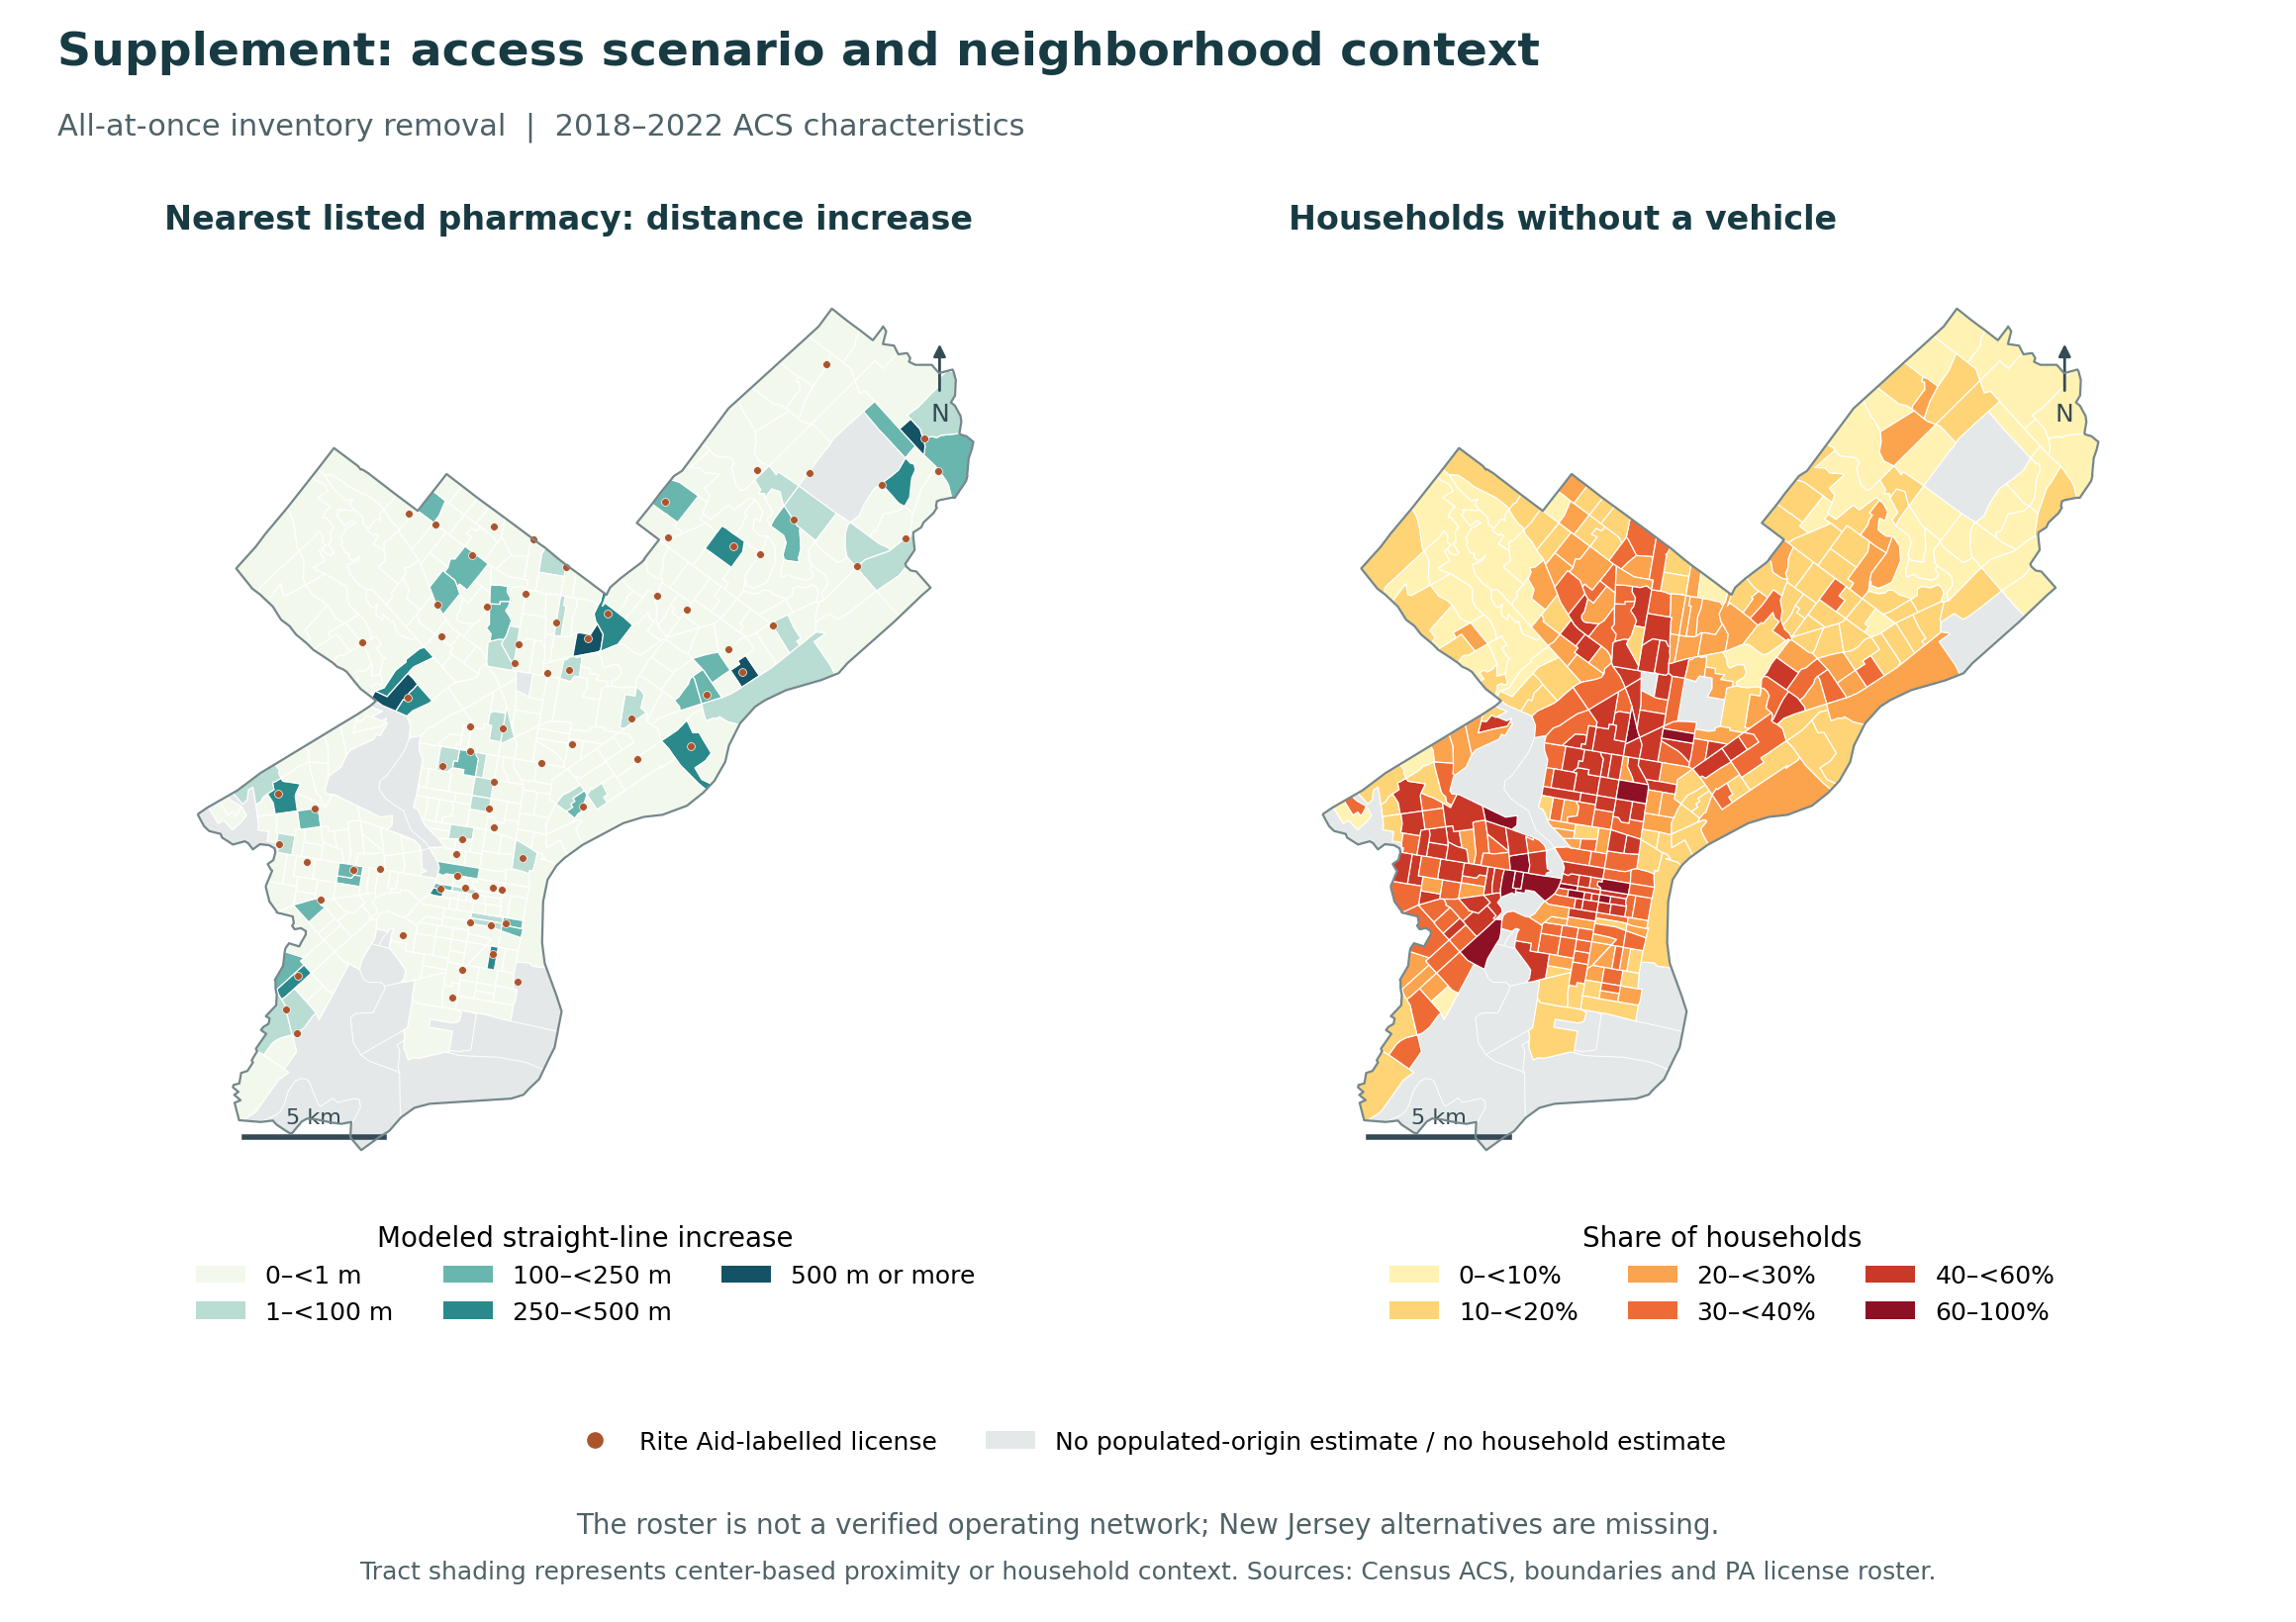

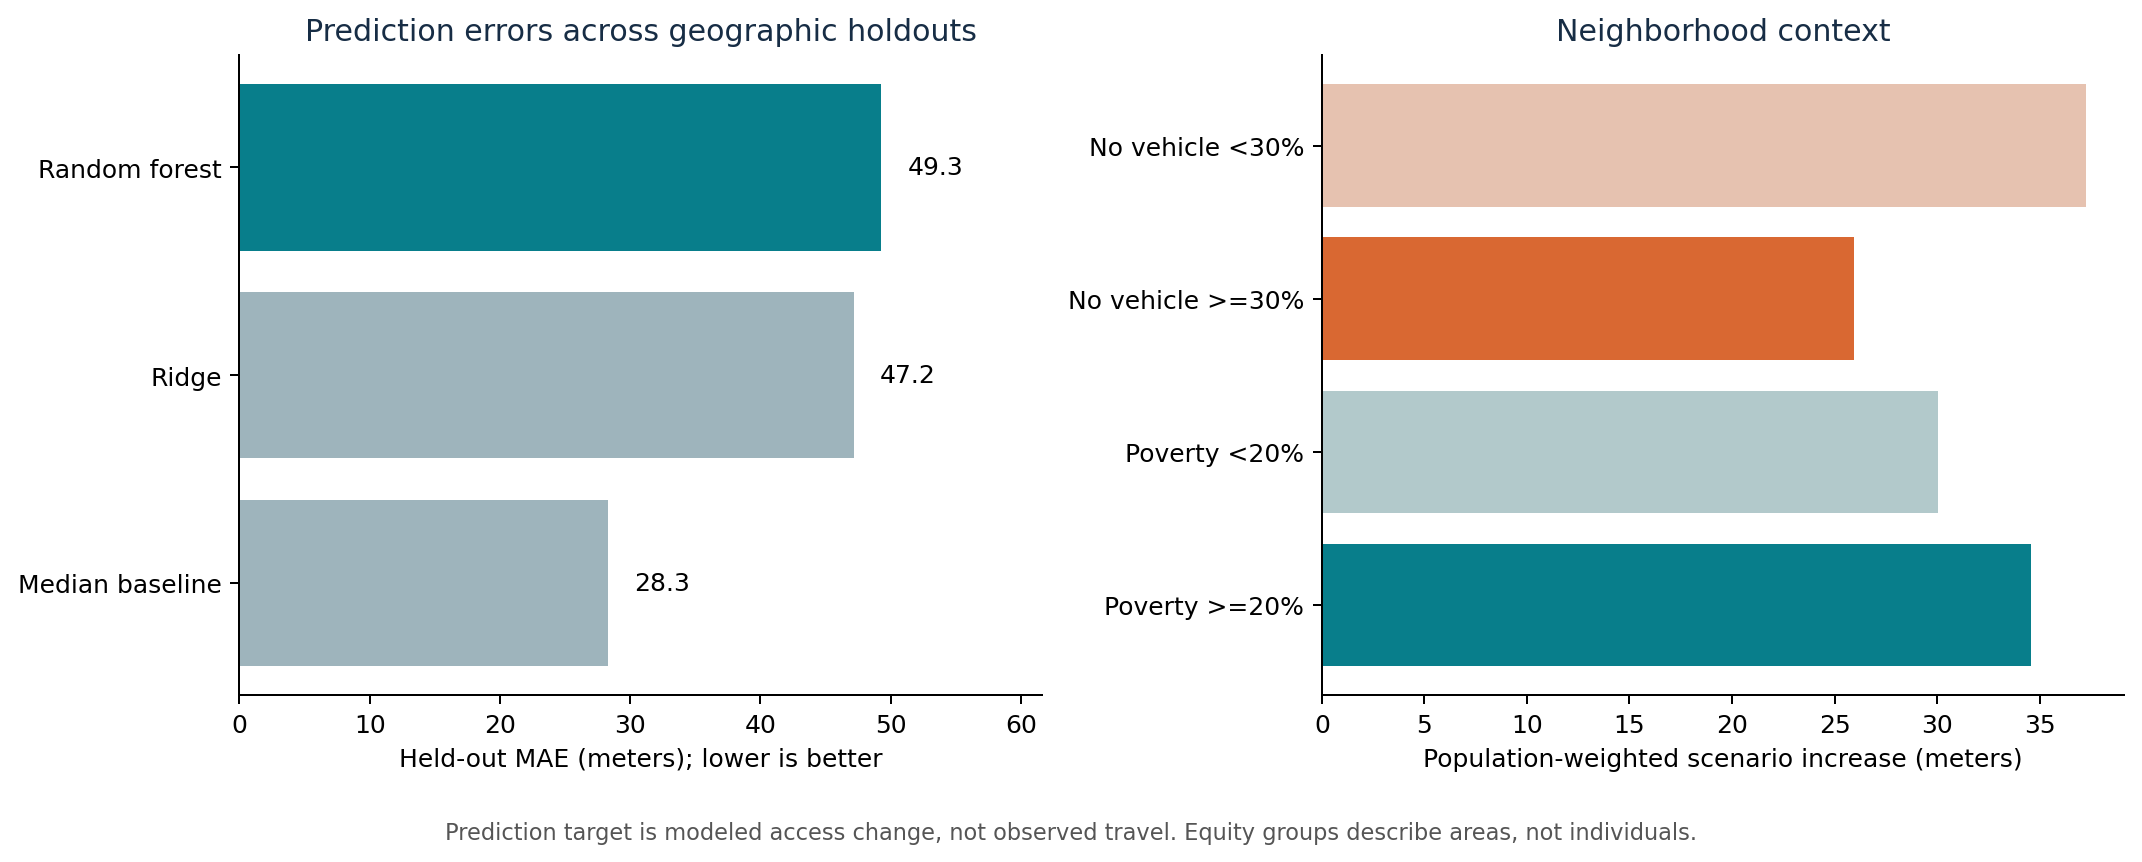

In [7]:
from src.pilot import summarize, figures
summary, equity = summarize(tracts, quality, metrics)
figures(tracts, pharmacies, metrics, equity)
display(Image(filename=str(OUT / 'access_equity_map.png')))
display(Image(filename=str(OUT / 'model_and_equity.png')))

### Interpretation of prediction errors
Lower MAE/RMSE is better; negative R² is possible out of sample. A zero-heavy target rewards the median baseline on MAE. A small improvement in RMSE alongside worse MAE does not establish useful predictive performance. Do not tune on these held-out results and then present the same folds as untouched validation.

The substantial inventory sensitivity is a data-validity warning. Before estimating historical impacts, the operating network needs manual and temporal validation.

In [8]:
ranking = metrics.sort_values('mae_m')
print('Lowest spatially held-out MAE:', ranking.iloc[0]['model'])
rf = metrics.set_index('model').loc['Random forest']
base = metrics.set_index('model').loc['Median baseline']
print(f'Random forest MAE: {rf.mae_m:.1f} m; median baseline MAE: {base.mae_m:.1f} m.')
print('The prediction comparison does not establish a causal effect or useful prediction of real travel.')
display(pd.read_csv(OUT / 'ml_fold_metrics.csv').round(2))

Lowest spatially held-out MAE: Median baseline
Random forest MAE: 49.3 m; median baseline MAE: 28.3 m.
The prediction comparison does not establish a causal effect or useful prediction of real travel.


,model,fold,n_train,n_test,mae_m,rmse_m
0,Median baseline,0,257,67,12.25,49.16
1,Ridge,0,257,67,32.93,51.41
2,Random forest,0,257,67,33.72,51.50
3,Median baseline,1,304,36,61.23,218.96
4,Ridge,1,304,36,71.15,208.12
5,Random forest,1,304,36,77.14,209.48
6,Median baseline,2,216,116,21.21,68.18
7,Ridge,2,216,116,37.02,65.40
8,Random forest,2,216,116,42.02,68.33
9,Median baseline,3,274,58,37.16,115.18


## 6. Equity is an area-level comparison
The table weights tract-origin scenarios by tract population. A second weighting by households without a vehicle is also reported. It cannot reveal the experience of individual residents, and group-specific sample means do not estimate causal heterogeneity. ACS uncertainty is retained in the source but not propagated in these pilot summaries.

In [9]:
display(equity.round(2))
display(pd.Series({
    'Populated tracts': summary['tracts_populated'],
    'Tract centroids with an increase >1 m': summary['populated_tracts_with_any_increase'],
    'Population-weighted scenario increase, m': summary['population_weighted_increment_m'],
    'No-vehicle-household-weighted increase, m': summary['no_vehicle_household_weighted_increment_m'],
    'Nonborder population-weighted increase, m': summary['nonborder_population_weighted_increment_m']
}, name='scenario_summary').round(2))

,group,n_tracts,population,population_weighted_increment_m
0,All populated tracts,391,1593208,32.39
1,Poverty rate at least 20%,192,828525,34.57
2,Poverty rate below 20%,197,764531,30.03
3,No-vehicle share at least 30%,176,682884,25.97
4,No-vehicle share below 30%,212,908907,37.26
5,Age 65+ share at least 20%,82,296501,18.28
6,Non-Hispanic Black share at least 50%,140,556992,21.82
7,Hispanic share at least 50%,24,115692,8.03


Populated tracts                             391.00
Tract centroids with an increase >1 m         67.00
Population-weighted scenario increase, m      32.39
No-vehicle-household-weighted increase, m     27.43
Nonborder population-weighted increase, m     30.34
Name: scenario_summary, dtype: float64

## 7. Conditional emissions scenarios
For 1,000 **hypothetical** person round trips, assume a car share, a route-detour factor and the share of journeys that create additional travel. The EPA's approximately 400 g CO₂ per gasoline-vehicle mile is a tailpipe factor; this is not lifecycle CO₂e or a measured Philadelphia fleet factor.

$$\Delta E=\Delta d\times 2\times r/1609.344\times N\times s_{car}\times s_{additional}\times 400/1000.$$

We assume one traveler per vehicle. There are no observed trips or mode shares in this pilot. A citywide annual emissions total would require unsupported assumptions and is not calculated.

In [10]:
from src.emissions import incremental_co2_kg
emissions = pd.read_csv(OUT / 'emissions_sensitivity.csv')
display(emissions.query('detour_factor == 1.3')[[
    'hypothetical_person_round_trips','car_share','additional_trip_share','additional_tailpipe_co2_kg']].round(2))
print('Scenario only. Changing trip chaining or mode assumptions changes these results.')

,hypothetical_person_round_trips,car_share,additional_trip_share,additional_tailpipe_co2_kg
2,1000,0.25,0.5,2.62
3,1000,0.25,1.0,5.23
8,1000,0.50,0.5,5.23
9,1000,0.50,1.0,10.47
14,1000,0.75,0.5,7.85
15,1000,0.75,1.0,15.70
20,1000,1.00,0.5,10.47
21,1000,1.00,1.0,20.93


Scenario only. Changing trip chaining or mode assumptions changes these results.


## 8. What is required before the causal study can run

| Input | Current status |
|---|---|
| Store-specific pharmacy dates | 24 company-reported 2025 last days plus four reported 2024 dates; independent date checks incomplete |
| Historical operating pharmacy network and replacements | Missing |
| Licensed 2022–2025 origin/POI mobility panel and coverage denominators | Not obtained |
| Historical street/transit routing; NJ alternatives | January 2025 PA streets acquired in notebook 04; transit and full NJ choice set missing |
| Validated mode information | Not obtained; foot traffic alone is insufficient |

The companion notebook checks for verified inputs before running any empirical contrast. The Python estimator excludes already-treated and flagged spillover controls, but still requires defensible parallel trends and selection assumptions. An optional R extension uses the authors' `did` implementation for a covariate-adjusted analysis; it has not been run.

Read [the full research protocol](../docs/research_protocol.md), [data access instructions](../docs/data_access.md), and [data dictionary](../docs/data_dictionary.md).

## 9. Results and interpretation
The tables and figures above preserve the original supplementary calculation. The expanded historical study has a different sample and destination rule.

This supplementary exercise estimates an all-at-once inventory sensitivity. Its 32.4-meter all-listed result and 282.1-meter chain-name result are not historical closure effects. Read [notebook 04](04_before_after_transfer_access.ipynb) for the dated transfer comparison and the full report for its interpretation.

## References

1. Pennsylvania Department of State and Department of Health. Find Naloxone at a Pharmacy Near Me Current Statewide. Dataset ysdx-4vmi; portal update July 1, 2025. [Source](https://data.pa.gov/Opioid-Related/Find-Naloxone-at-a-Pharmacy-Near-Me-Current-Statew/ysdx-4vmi/about_data)

2. U.S. Census Bureau. 2022 American Community Survey five-year Summary File. Tables B01001, B01003, B03002, B08201, B17001 and B19013; estimates cover 2018–2022. [Source](https://www.census.gov/programs-surveys/acs/data/summary-file.2022.html)

3. U.S. Census Bureau. 2022 Cartographic Boundary Files. Pennsylvania census tracts and United States counties at 1:500,000 scale. [Source](https://www.census.gov/geographies/mapping-files/time-series/geo/cartographic-boundary.html)

4. Philadelphia City Council. Resolution 240071. Pharmacy closures and access concerns. [Source](https://phila.legistar.com/LegislationDetail.aspx?ID=6503447&GUID=E7438EA1-5E3E-460A-9902-FCDE7D12D48B&FullText=1)

5. U.S. Environmental Protection Agency. Smart Growth and Transportation. Access to destinations and transportation choices. [Source](https://www.epa.gov/smartgrowth/smart-growth-and-transportation)

6. U.S. Environmental Protection Agency. Greenhouse Gas Emissions from a Typical Passenger Vehicle. Approximately 400 grams of tailpipe CO₂ per gasoline-vehicle mile. [Source](https://www.epa.gov/greenvehicles/greenhouse-gas-emissions-typical-passenger-vehicle)

7. Callaway, B., and Sant’Anna, P. H. C. (2021). Difference-in-Differences with Multiple Time Periods. Journal of Econometrics, 225(2), 200–230. [Source](https://doi.org/10.1016/j.jeconom.2020.12.001)

8. Butts, K. Difference-in-Differences Estimation with Spatial Spillovers. Working paper, arXiv:2105.03737. [Source](https://arxiv.org/abs/2105.03737)

9. Penn Libraries (2025). Penn Data Access Unlocked via Dewey Platform. May 21. [Source](https://www.library.upenn.edu/lippincott/datapoints/data-access-dewey-2025)

10. AmeriHealth Caritas Pennsylvania and Community HealthChoices (2025). Rite Aid pharmacy closure notice. June 5. Contextual evidence of closures and prescription transfers; not a store-specific event ledger. [Source](https://www.amerihealthcaritaschc.com/content/dam/amerihealth-caritas/acpchc/pdf/provider/resources/communications/2025/20250605-rite-aid-pharmacy-closure-notice.pdf.coredownload.inline.pdf)

11. Rite Aid Corporation et al. (2023). Store closing sales motion. U.S. Bankruptcy Court, District of New Jersey, case 23-18993-MBK, document 37, filed October 16. Exhibit A Schedule 1, PDF pages 54–56. Public mirror of court-filed document. [Source](https://cdns.abclocal.go.com/three/kabc/101823-kabc-rite-aid-doc.pdf)

12. New Rite Aid LLC et al. (2025). Sixth notice of additional closing locations. U.S. Bankruptcy Court, District of New Jersey, case 25-14861-MBK, document 743, filed June 6. Exhibit 1, PDF pages 5–8. Public mirror of court-filed document. [Source](https://npr.brightspotcdn.com/f8/c8/faad678e424db35665a541d7ce0a/25-06-06-store-closure-filing.pdf)

13. Rite Aid (2025). Pharmacy Closure and Transfer List. Internet Archive capture October 4, 2025; 1,025 national rows. [Source](https://web.archive.org/web/20251004155916/https://content.riteaid.com/new-pharmacy-location.html)

14. Keystone First VIP Choice (2025). Pharmacy Directory. Updated May 5, 2025. Philadelphia Rite Aid entries, printed pages 105–108. [Source](https://q1.keystonefirstvipchoice.com/content/dam/keystone-first/vip-choice/pdf/2025-pharmacy-directory.pdf.coredownload.inline.pdf)

15. OpenStreetMap contributors and Geofabrik (2025). Pennsylvania historical extract, January 1, 2025. ODbL 1.0. Network filtering and checksums are documented in the repository. [Source](https://download.geofabrik.de/north-america/us/pennsylvania.html)

16. Veeramachaneni, S., Ramachandran, S., and Barnard, M. (2026). Bulk Prescription Transfers and Access After Chain Pharmacy Closures. JAMA Health Forum, 7(7), e262070. [Source](https://doi.org/10.1001/jamahealthforum.2026.2070)

17. McCarthy, E. (2025). Philly’s last Rite Aid stores will close in late August. The Philadelphia Inquirer, July 9. [Source](https://www.inquirer.com/business/rite-aid-philadelphia-stores-closing-20250709.html)

18. McCarthy, E. (2025). All Rite Aid pharmacies are officially closed in Pa., N.J. The Philadelphia Inquirer, August 23. [Source](https://www.inquirer.com/business/health/rite-aid-pharmacies-closed-pennsylvania-new-jersey-20250823.html)

19. Ajamu, R. (2024). Rite Aid to close its Germantown Avenue location. Resolve Philly, April 16; updated July 17. [Source](https://resolvephilly.org/gih/rite-aid-to-close-its-germantown-avenue-location-leaving-some-residents-without-a-nearby-pharmacy/)

20. McCarthy, E. (2024). Six more Rite Aid stores are closing in Philly and its suburbs. The Philadelphia Inquirer, April 8. [Source](https://www.inquirer.com/business/rite-aid-closures-philadelphia-chester-county-south-jersey-20240408.html)

21. Perez-Castells, A. (2024). Another Center City Rite Aid is closing as the company continues to downsize amid bankruptcy. The Philadelphia Inquirer, January 8. [Source](https://www.inquirer.com/business/rite-aid-pharmacy-closed-center-city-20240108.html)

22. McCarthy, E. (2024). What happens after a Philly neighborhood’s last chain pharmacy shuts its doors. The Philadelphia Inquirer, February 4. [Source](https://www.inquirer.com/business/rite-aid-bankruptcy-south-philadelphia-20240204.html)

23. Perez-Castells, A. (2023). More Rite Aid pharmacies are closing in the Philadelphia region before the end of the year. The Philadelphia Inquirer, December 1. [Source](https://www.inquirer.com/business/rite-aid-store-closed-phamacy-bankruptcy-20231201.html)

24. Keele, L. J., and Titiunik, R. (2015). Geographic Boundaries as Regression Discontinuities. Political Analysis, 23(1), 127–155. [Source](https://doi.org/10.1093/pan/mpu014)

25. Angrist, J. D., Imbens, G. W., and Rubin, D. B. (1996). Identification of Causal Effects Using Instrumental Variables. Journal of the American Statistical Association, 91(434), 444–455. [Source](https://doi.org/10.1080/01621459.1996.10476902)

See [additional source notes](../docs/references.md) for mobility and software documentation.